<a href="https://colab.research.google.com/github/dudekulapeeravali2537sse-bot/ITA0616/blob/main/EXP_16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Iris Dataset Loaded Successfully
Dataset Shape: (150, 4)

Algorithm: Logistic Regression
Accuracy: 93.33 %

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Algorithm: KNN
Accuracy: 93.33 %

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30


Algorithm: Decision Tree
Accuracy: 93.33 %

Clas

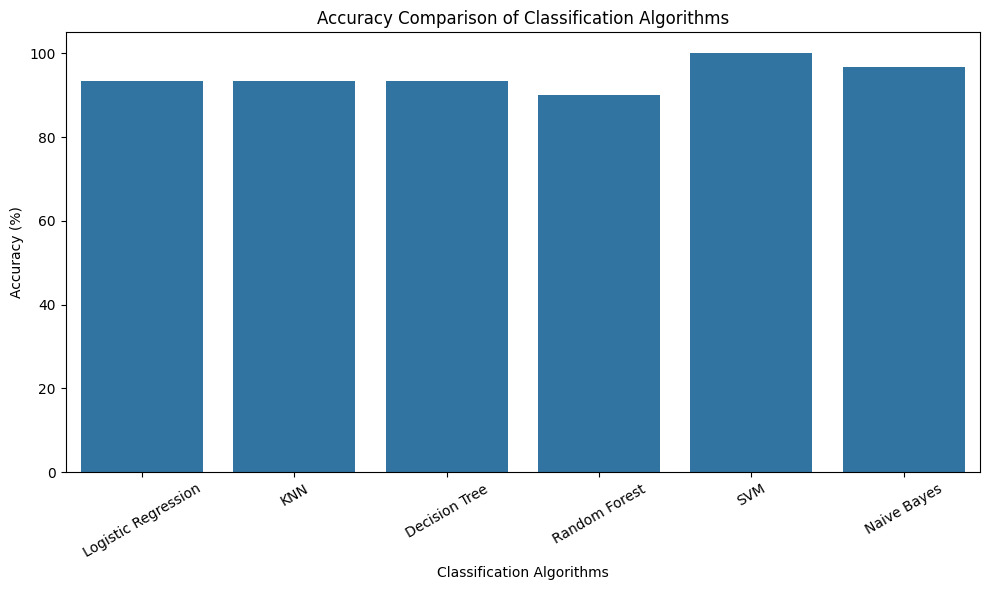

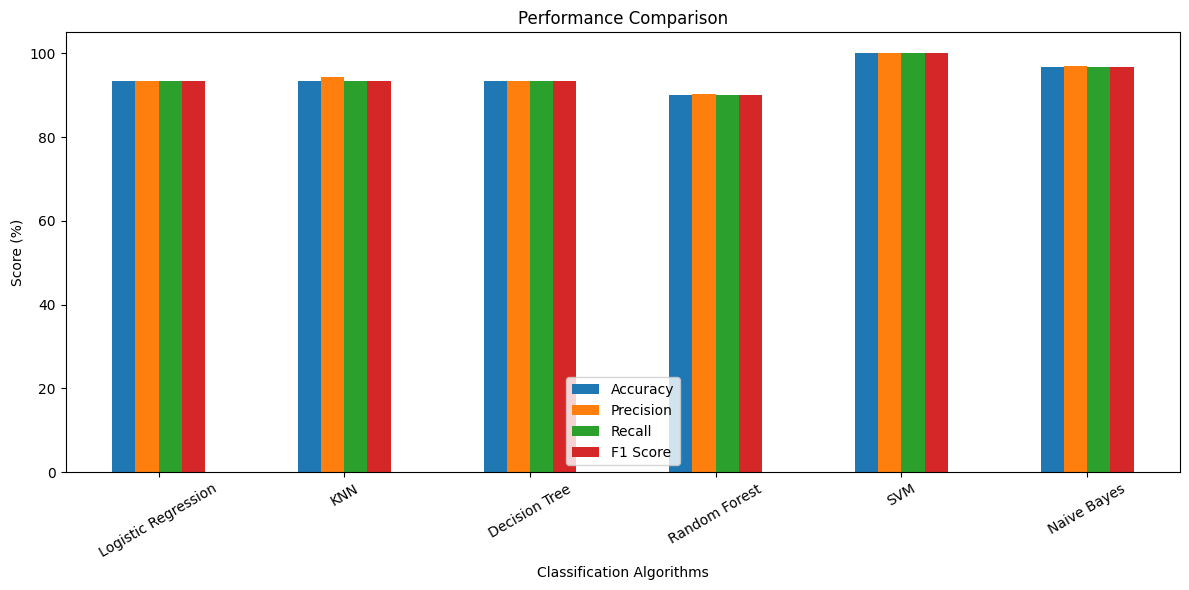

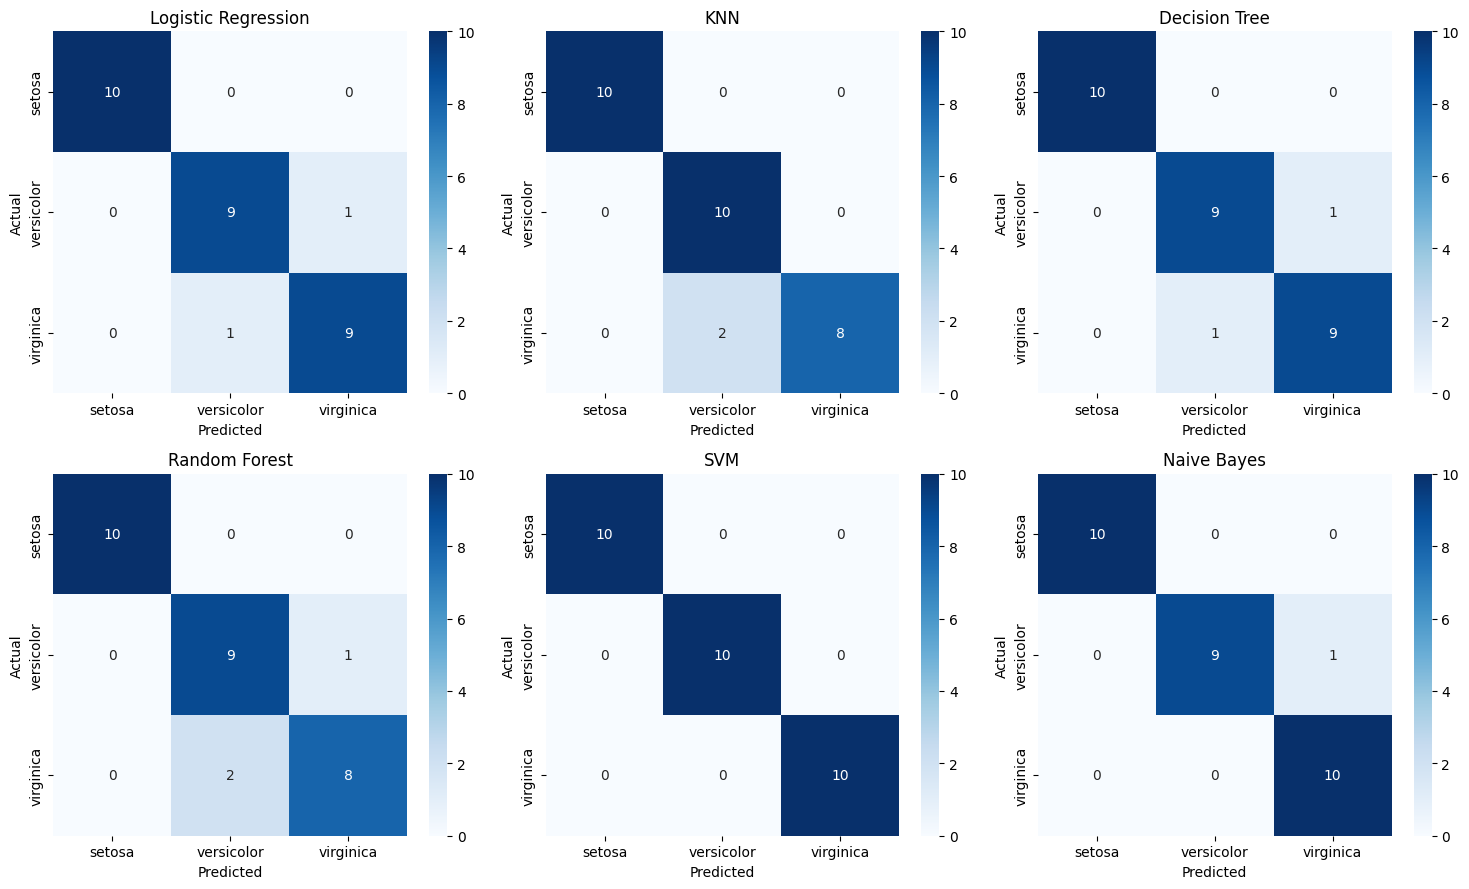


Results saved successfully!


In [1]:

# Comparison of Different Classification Algorithms

# Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Classification Algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# Evaluation Metrics
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

# Step 1: Load Dataset
iris = load_iris()

X = iris.data
y = iris.target

print("Iris Dataset Loaded Successfully")
print("Dataset Shape:", X.shape)

# Step 2: Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Step 3: Define Classification Models
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),

    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "SVM": make_pipeline(
        StandardScaler(),
        SVC(kernel='linear')
    ),

    "Naive Bayes": GaussianNB()
}

# Step 4: Train and Evaluate Models
results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, average='weighted'
    )
    recall = recall_score(
        y_test, y_pred, average='weighted'
    )
    f1 = f1_score(
        y_test, y_pred, average='weighted'
    )

    results.append({
        "Algorithm": name,
        "Accuracy": round(accuracy * 100, 2),
        "Precision": round(precision * 100, 2),
        "Recall": round(recall * 100, 2),
        "F1 Score": round(f1 * 100, 2)
    })

    print("\nAlgorithm:", name)
    print("Accuracy:", round(accuracy * 100, 2), "%")

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names
    ))

# Step 5: Display Comparison Table
results_df = pd.DataFrame(results)

print("\nCLASSIFICATION ALGORITHM COMPARISON")
print(results_df.to_string(index=False))

# Step 6: Find Best Algorithm
best = results_df.loc[
    results_df["Accuracy"].idxmax()
]

print("\nBEST CLASSIFICATION ALGORITHM")
print("Algorithm:", best["Algorithm"])
print("Accuracy:", best["Accuracy"], "%")

# Step 7: Accuracy Comparison Graph
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Algorithm",
    y="Accuracy"
)

plt.title("Accuracy Comparison of Classification Algorithms")
plt.xlabel("Classification Algorithms")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=30)
plt.ylim(0, 105)
plt.tight_layout()
plt.savefig("accuracy_comparison.png")
plt.show()

# Step 8: Compare All Metrics
metrics = results_df.set_index("Algorithm")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
]

metrics.plot(kind="bar", figsize=(12, 6))

plt.title("Performance Comparison")
plt.ylabel("Score (%)")
plt.xlabel("Classification Algorithms")
plt.xticks(rotation=30)
plt.ylim(0, 105)
plt.tight_layout()
plt.savefig("performance_comparison.png")
plt.show()

# Step 9: Confusion Matrix for Every Algorithm
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, (name, model) in zip(
    axes.flatten(), models.items()
):

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=iris.target_names,
        yticklabels=iris.target_names,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.savefig("confusion_matrices.png")
plt.show()

# Step 10: Save Results
results_df.to_csv(
    "classification_results.csv",
    index=False
)

print("\nResults saved successfully!")
